
Dari hasil scrap data tokopedia, kami akan melakukan beberapa langkah berikut:
*   Prepocessing data
*   NLP
    1. tokenisasi
       Operasi pemisahan string input berdasarkan tiap
        kata yang menyusunya
    2. Filtering
       pembersihan kata-kata yang dianggap tidak penting seperti tanda baca dan lainnya
    3. Stemming
       Cara untuk penataan dan pemaparan berbagai bentuk (variants) dari suatu kata menjadi bentuk kata dasarnya (stem)
*   Klasifikasi menggunakan k-nearest neighbor
*   Model dan pengujian model





In [ ]:
!pip install google-play-scraper

In [ ]:
from google_play_scraper import app

import pandas as pd

import numpy as np

In [ ]:
# Scrape All available reviews

from google_play_scraper import Sort, reviews_all

result = reviews_all(
    'com.tokopedia.tkpd',
    sleep_milliseconds=0, # defaults to 0
    lang='id', # defaults to 'en'
    country='id', # defaults to 'us'
    sort=Sort.NEWEST, # defaults to Sort.MOST_RELEVANT , you can use Sort.NEWEST to get newst reviews
)


In [ ]:
df = pd.DataFrame(np.array(result),columns=['review'])

df= df.join(pd.DataFrame(df.pop('review').tolist()))

df

In [ ]:
df.shape

In [ ]:
from datetime import datetime
# Review 14 hari terakhir
start_date = datetime(2024, 5, 25)
end_date = datetime(2024, 6, 9)
filtered_df = df[(df['at'] >= start_date) & (df['at'] <= end_date)]
filtered_df

In [ ]:
filtered_df.shape

In [ ]:
filtered_df.to_csv("scrapped_dataTokopedia.csv", index = False)

In [ ]:
import pandas as pd
df = pd.read_csv("scrapped_dataTokopedia.csv", usecols=['reviewId', 'content', 'score','at'])
df

,reviewId,content,score,at
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25
1,7ad1382c-fdaa-484d-9883-844581ce4bc3,👎,1,2024-06-08 23:55:26
2,917fb1ac-55e5-43b1-8dd5-30a7d1a80aed,我喜欢这个应用程序🤗🤗🤗🤗,5,2024-06-08 23:41:37
3,008f9301-b71e-4216-abbe-dbbbc31512f5,Aneh mesen 2 yg harusnya jadi tpi beratnya set...,3,2024-06-08 23:36:20
4,04372396-d010-4162-84ac-886ea7734819,toko terbaik,5,2024-06-08 23:23:56
...,...,...,...,...
2430,c3900907-708c-4a91-b6b7-0fbe2c2ef910,Masak ya belum tup. Udah bilang melebihi batas...,1,2024-05-25 03:46:19
2431,c43b8c74-b4b4-4483-b7c5-a63eaabe16fd,terima kasih,5,2024-05-25 01:20:50
2432,8c1984ba-71ab-4b66-8a2c-ee51b3a0007b,"Gila bener, pengiriman sangat lambat,saya kira...",1,2024-05-25 01:04:20
2433,133f0748-2288-42b9-b5d2-89f8f26b7e75,"APK BE6O DITUDUH PUNYA AKUN GANDA GBLK BENER, ...",1,2024-05-25 00:44:33


## Prepocessing

**Import Library**

In [ ]:
!pip install Sastrawi

In [ ]:
import numpy as np
import pandas as pd
import nltk
import string
import re

#import sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

#import stopword
from nltk.corpus import stopwords

In [ ]:
df = pd.read_csv("scrapped_dataTokopedia.csv", usecols=['reviewId', 'content', 'score','at'])
df

,reviewId,content,score,at
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25
1,7ad1382c-fdaa-484d-9883-844581ce4bc3,👎,1,2024-06-08 23:55:26
2,917fb1ac-55e5-43b1-8dd5-30a7d1a80aed,我喜欢这个应用程序🤗🤗🤗🤗,5,2024-06-08 23:41:37
3,008f9301-b71e-4216-abbe-dbbbc31512f5,Aneh mesen 2 yg harusnya jadi tpi beratnya set...,3,2024-06-08 23:36:20
4,04372396-d010-4162-84ac-886ea7734819,toko terbaik,5,2024-06-08 23:23:56
...,...,...,...,...
2430,c3900907-708c-4a91-b6b7-0fbe2c2ef910,Masak ya belum tup. Udah bilang melebihi batas...,1,2024-05-25 03:46:19
2431,c43b8c74-b4b4-4483-b7c5-a63eaabe16fd,terima kasih,5,2024-05-25 01:20:50
2432,8c1984ba-71ab-4b66-8a2c-ee51b3a0007b,"Gila bener, pengiriman sangat lambat,saya kira...",1,2024-05-25 01:04:20
2433,133f0748-2288-42b9-b5d2-89f8f26b7e75,"APK BE6O DITUDUH PUNYA AKUN GANDA GBLK BENER, ...",1,2024-05-25 00:44:33


**kategori label**

1.   rating >3 akan diberi label 1
2.   rating =3 akan diberi label 0
3. rating < 3 akan diberi label -1



In [ ]:
df['label'] = df['score'].apply(lambda x: '1' if x >= 4 else ('-1' if x <= 2 else '0'))
df

,reviewId,content,score,at,label
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25,1
1,7ad1382c-fdaa-484d-9883-844581ce4bc3,👎,1,2024-06-08 23:55:26,-1
2,917fb1ac-55e5-43b1-8dd5-30a7d1a80aed,我喜欢这个应用程序🤗🤗🤗🤗,5,2024-06-08 23:41:37,1
3,008f9301-b71e-4216-abbe-dbbbc31512f5,Aneh mesen 2 yg harusnya jadi tpi beratnya set...,3,2024-06-08 23:36:20,0
4,04372396-d010-4162-84ac-886ea7734819,toko terbaik,5,2024-06-08 23:23:56,1
...,...,...,...,...,...
2430,c3900907-708c-4a91-b6b7-0fbe2c2ef910,Masak ya belum tup. Udah bilang melebihi batas...,1,2024-05-25 03:46:19,-1
2431,c43b8c74-b4b4-4483-b7c5-a63eaabe16fd,terima kasih,5,2024-05-25 01:20:50,1
2432,8c1984ba-71ab-4b66-8a2c-ee51b3a0007b,"Gila bener, pengiriman sangat lambat,saya kira...",1,2024-05-25 01:04:20,-1
2433,133f0748-2288-42b9-b5d2-89f8f26b7e75,"APK BE6O DITUDUH PUNYA AKUN GANDA GBLK BENER, ...",1,2024-05-25 00:44:33,-1


In [ ]:
column_name = 'label'
if column_name in df.columns:
  print(df[column_name].value_counts())


label
1     1319
-1     996
0      120
Name: count, dtype: int64


**Check Missing Value**

In [ ]:
df.isnull().sum()

reviewId    0
content     0
score       0
at          0
label       0
dtype: int64

**Check Duplicate Data**


In [ ]:
df.duplicated().sum()

0

###**NLP (Natural Language Processing)**

**Case Folding**

In [ ]:
df['case_folding'] = df['content'].apply(lambda x : x.lower())
df.head()

,reviewId,content,score,at,label,case_folding
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25,1,baik sekali
1,7ad1382c-fdaa-484d-9883-844581ce4bc3,👎,1,2024-06-08 23:55:26,-1,👎
2,917fb1ac-55e5-43b1-8dd5-30a7d1a80aed,我喜欢这个应用程序🤗🤗🤗🤗,5,2024-06-08 23:41:37,1,我喜欢这个应用程序🤗🤗🤗🤗
3,008f9301-b71e-4216-abbe-dbbbc31512f5,Aneh mesen 2 yg harusnya jadi tpi beratnya set...,3,2024-06-08 23:36:20,0,aneh mesen 2 yg harusnya jadi tpi beratnya set...
4,04372396-d010-4162-84ac-886ea7734819,toko terbaik,5,2024-06-08 23:23:56,1,toko terbaik


**Remove Punctuation**

In [ ]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
def remove_punctuation(series):
    text = "".join([word for word in series if word not in string.punctuation])
    return text
df['remove_punc'] = df['case_folding'].apply(remove_punctuation)
df.head()

,reviewId,content,score,at,label,case_folding,remove_punc
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25,1,baik sekali,baik sekali
1,7ad1382c-fdaa-484d-9883-844581ce4bc3,👎,1,2024-06-08 23:55:26,-1,👎,👎
2,917fb1ac-55e5-43b1-8dd5-30a7d1a80aed,我喜欢这个应用程序🤗🤗🤗🤗,5,2024-06-08 23:41:37,1,我喜欢这个应用程序🤗🤗🤗🤗,我喜欢这个应用程序🤗🤗🤗🤗
3,008f9301-b71e-4216-abbe-dbbbc31512f5,Aneh mesen 2 yg harusnya jadi tpi beratnya set...,3,2024-06-08 23:36:20,0,aneh mesen 2 yg harusnya jadi tpi beratnya set...,aneh mesen 2 yg harusnya jadi tpi beratnya set...
4,04372396-d010-4162-84ac-886ea7734819,toko terbaik,5,2024-06-08 23:23:56,1,toko terbaik,toko terbaik


**Remove Emoticon**

In [ ]:
def remove_emoji(text):
    emoji_pattern = re.compile("["
                           u"\U0001F600-\U0001F64F"  # emoticons
                           u"\U0001F300-\U0001F5FF"  # symbols & pictographs
                           u"\U0001F680-\U0001F6FF"  # transport & map symbols
                           u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                           u"\U00002702-\U000027B0"
                           u"\U000024C2-\U0001F251"
                           "]+", flags=re.UNICODE)
    return emoji_pattern.sub(r'', text)
df['remove_emoji'] = df['remove_punc'].apply(lambda x : remove_emoji(x))
df.head()

,reviewId,content,score,at,label,case_folding,remove_punc,remove_emoji
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25,1,baik sekali,baik sekali,baik sekali
1,7ad1382c-fdaa-484d-9883-844581ce4bc3,👎,1,2024-06-08 23:55:26,-1,👎,👎,
2,917fb1ac-55e5-43b1-8dd5-30a7d1a80aed,我喜欢这个应用程序🤗🤗🤗🤗,5,2024-06-08 23:41:37,1,我喜欢这个应用程序🤗🤗🤗🤗,我喜欢这个应用程序🤗🤗🤗🤗,🤗🤗🤗🤗
3,008f9301-b71e-4216-abbe-dbbbc31512f5,Aneh mesen 2 yg harusnya jadi tpi beratnya set...,3,2024-06-08 23:36:20,0,aneh mesen 2 yg harusnya jadi tpi beratnya set...,aneh mesen 2 yg harusnya jadi tpi beratnya set...,aneh mesen 2 yg harusnya jadi tpi beratnya set...
4,04372396-d010-4162-84ac-886ea7734819,toko terbaik,5,2024-06-08 23:23:56,1,toko terbaik,toko terbaik,toko terbaik


**More**

In [ ]:
# Clean text

def remove_url(text):
    url = re.compile(r'https?://\S+|www\.\S+')
    return url.sub(r'',text)

def remove_html(text):
    html=re.compile(r'<.*?>')
    return html.sub(r'',text)

def seperate_alphanumeric(text):
    words = text
    words = re.findall(r"[^\W\d_]+|\d+", words)
    return " ".join(words)

def cont_rep_char(text):
    tchr = text.group(0)

    if len(tchr) > 1:
        return tchr[0:2]

def unique_char(rep, text):
    substitute = re.sub(r'(\w)\1+', rep, text)
    return substitute

def char(text):
    substitute = re.sub(r'[^a-zA-Z]',' ',text)
    return substitute

# Apply functions on OriginalTweet
df['remove_emoji'] = df['remove_emoji'].apply(lambda x : remove_url(x))
df['remove_emoji'] = df['remove_emoji'].apply(lambda x : seperate_alphanumeric(x))
df['remove_emoji'] = df['remove_emoji'].apply(lambda x : unique_char(cont_rep_char,x))
df['remove_emoji'] = df['remove_emoji'].apply(lambda x : char(x))
df.head()

,reviewId,content,score,at,label,case_folding,remove_punc,remove_emoji
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25,1,baik sekali,baik sekali,baik sekali
1,7ad1382c-fdaa-484d-9883-844581ce4bc3,👎,1,2024-06-08 23:55:26,-1,👎,👎,
2,917fb1ac-55e5-43b1-8dd5-30a7d1a80aed,我喜欢这个应用程序🤗🤗🤗🤗,5,2024-06-08 23:41:37,1,我喜欢这个应用程序🤗🤗🤗🤗,我喜欢这个应用程序🤗🤗🤗🤗,
3,008f9301-b71e-4216-abbe-dbbbc31512f5,Aneh mesen 2 yg harusnya jadi tpi beratnya set...,3,2024-06-08 23:36:20,0,aneh mesen 2 yg harusnya jadi tpi beratnya set...,aneh mesen 2 yg harusnya jadi tpi beratnya set...,aneh mesen yg harusnya jadi tpi beratnya set...
4,04372396-d010-4162-84ac-886ea7734819,toko terbaik,5,2024-06-08 23:23:56,1,toko terbaik,toko terbaik,toko terbaik


In [ ]:
df.shape

(2435, 8)

**Remove Stopwords**

In [ ]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Acer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
stopwords_indonesia = stopwords.words('indonesian')
stopwords_indonesia

['ada',
 'adalah',
 'adanya',
 'adapun',
 'agak',
 'agaknya',
 'agar',
 'akan',
 'akankah',
 'akhir',
 'akhiri',
 'akhirnya',
 'aku',
 'akulah',
 'amat',
 'amatlah',
 'anda',
 'andalah',
 'antar',
 'antara',
 'antaranya',
 'apa',
 'apaan',
 'apabila',
 'apakah',
 'apalagi',
 'apatah',
 'artinya',
 'asal',
 'asalkan',
 'atas',
 'atau',
 'ataukah',
 'ataupun',
 'awal',
 'awalnya',
 'bagai',
 'bagaikan',
 'bagaimana',
 'bagaimanakah',
 'bagaimanapun',
 'bagi',
 'bagian',
 'bahkan',
 'bahwa',
 'bahwasanya',
 'baik',
 'bakal',
 'bakalan',
 'balik',
 'banyak',
 'bapak',
 'baru',
 'bawah',
 'beberapa',
 'begini',
 'beginian',
 'beginikah',
 'beginilah',
 'begitu',
 'begitukah',
 'begitulah',
 'begitupun',
 'bekerja',
 'belakang',
 'belakangan',
 'belum',
 'belumlah',
 'benar',
 'benarkah',
 'benarlah',
 'berada',
 'berakhir',
 'berakhirlah',
 'berakhirnya',
 'berapa',
 'berapakah',
 'berapalah',
 'berapapun',
 'berarti',
 'berawal',
 'berbagai',
 'berdatangan',
 'beri',
 'berikan',
 'berikut'

In [ ]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

#tokenize
from nltk.tokenize import TweetTokenizer

# Happy Emoticons
emoticons_happy = set([
    ':-)', ':)', ';)', ':o)', ':]', ':3', ':c)', ':>', '=]', '8)', '=)', ':}',
    ':^)', ':-D', ':D', '8-D', '8D', 'x-D', 'xD', 'X-D', 'XD', '=-D', '=D',
    '=-3', '=3', ':-))', ":'-)", ":')", ':*', ':^*', '>:P', ':-P', ':P', 'X-P',
    'x-p', 'xp', 'XP', ':-p', ':p', '=p', ':-b', ':b', '>:)', '>;)', '>:-)',
    '<3'
    ])

# Sad Emoticons
emoticons_sad = set([
    ':L', ':-/', '>:/', ':S', '>:[', ':@', ':-(', ':[', ':-||', '=L', ':<',
    ':-[', ':-<', '=\\', '=/', '>:(', ':(', '>.<', ":'-(", ":'(", ':\\', ':-c',
    ':c', ':{', '>:\\', ';('
    ])

# all emoticons (happy + sad)
emoticons = emoticons_happy.union(emoticons_sad)

def clean_tweets(tweet):
    # remove stock market tickers like $GE
    tweet = re.sub(r'\$\w*', '', tweet)

    # remove old style retweet text "RT"
    tweet = re.sub(r'^RT[\s]+', '', tweet)

    # remove hyperlinks
    tweet = re.sub(r'https?:\/\/.*[\r\n]*', '', tweet)

    # remove hashtags
    # only removing the hash # sign from the word
    tweet = re.sub(r'#', '', tweet)

    #remove coma
    tweet = re.sub(r',','',tweet)

    #remove angka
    tweet = re.sub('[0-9]+', '', tweet)


    # tokenize tweets
    tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
    tweet_tokens = tokenizer.tokenize(tweet)

    tweets_clean = []
    for word in tweet_tokens:
        if (word not in stopwords_indonesia and # remove stopwords
              word not in emoticons and # remove emoticons
                word not in string.punctuation): # remove punctuation
            #tweets_clean.append(word)
            stem_word = stemmer.stem(word) # stemming word
            tweets_clean.append(stem_word)

    return tweets_clean
df['tweet_clean'] = df['remove_emoji'].apply(lambda x: clean_tweets(x))
df

,reviewId,content,score,at,label,case_folding,remove_punc,remove_emoji,tweet_clean
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25,1,baik sekali,baik sekali,baik sekali,[]
1,7ad1382c-fdaa-484d-9883-844581ce4bc3,👎,1,2024-06-08 23:55:26,-1,👎,👎,,[]
2,917fb1ac-55e5-43b1-8dd5-30a7d1a80aed,我喜欢这个应用程序🤗🤗🤗🤗,5,2024-06-08 23:41:37,1,我喜欢这个应用程序🤗🤗🤗🤗,我喜欢这个应用程序🤗🤗🤗🤗,,[]
3,008f9301-b71e-4216-abbe-dbbbc31512f5,Aneh mesen 2 yg harusnya jadi tpi beratnya set...,3,2024-06-08 23:36:20,0,aneh mesen 2 yg harusnya jadi tpi beratnya set...,aneh mesen 2 yg harusnya jadi tpi beratnya set...,aneh mesen yg harusnya jadi tpi beratnya set...,"[aneh, mesen, yg, tpi, berat, tara, mesen]"
4,04372396-d010-4162-84ac-886ea7734819,toko terbaik,5,2024-06-08 23:23:56,1,toko terbaik,toko terbaik,toko terbaik,"[toko, baik]"
...,...,...,...,...,...,...,...,...,...
2430,c3900907-708c-4a91-b6b7-0fbe2c2ef910,Masak ya belum tup. Udah bilang melebihi batas...,1,2024-05-25 03:46:19,-1,masak ya belum tup. udah bilang melebihi batas...,masak ya belum tup udah bilang melebihi batas ...,masak ya belum tup udah bilang melebihi batas ...,"[masak, ya, tup, udah, bilang, lebih, batas, g..."
2431,c43b8c74-b4b4-4483-b7c5-a63eaabe16fd,terima kasih,5,2024-05-25 01:20:50,1,terima kasih,terima kasih,terima kasih,"[terima, kasih]"
2432,8c1984ba-71ab-4b66-8a2c-ee51b3a0007b,"Gila bener, pengiriman sangat lambat,saya kira...",1,2024-05-25 01:04:20,-1,"gila bener, pengiriman sangat lambat,saya kira...",gila bener pengiriman sangat lambatsaya kira p...,gila bener pengiriman sangat lambatsaya kira p...,"[gila, bener, kirim, lambatsaya, kirim, cepat,..."
2433,133f0748-2288-42b9-b5d2-89f8f26b7e75,"APK BE6O DITUDUH PUNYA AKUN GANDA GBLK BENER, ...",1,2024-05-25 00:44:33,-1,"apk be6o dituduh punya akun ganda gblk bener, ...",apk be6o dituduh punya akun ganda gblk bener m...,apk be o dituduh punya akun ganda gblk bener...,"[apk, be, o, tuduh, akun, ganda, gblk, bener, ..."


In [ ]:
df.sort_values("tweet_clean", inplace = True)
df

,reviewId,content,score,at,label,case_folding,remove_punc,remove_emoji,tweet_clean
0,57e79a26-5411-49ba-95e2-9dde4c6ac587,baik sekali,5,2024-06-08 23:56:25,1,baik sekali,baik sekali,baik sekali,[]
1467,0b438c08-c5c4-4cd3-9003-6c26de6b0597,sangat baik,5,2024-05-31 17:26:00,1,sangat baik,sangat baik,sangat baik,[]
1452,fe22897d-835e-41e1-acbb-1e13a162c01d,baik,5,2024-05-31 19:34:22,1,baik,baik,baik,[]
1379,1e0fa214-6b9d-4819-be55-267d08a5f39f,👍👍👍👍👍,5,2024-06-01 08:37:14,1,👍👍👍👍👍,👍👍👍👍👍,,[]
1363,bd3be12c-28a2-4fae-ab1a-1fc60aaa43dc,baik,5,2024-06-01 11:24:54,1,baik,baik,baik,[]
...,...,...,...,...,...,...,...,...,...
2278,43a50448-8072-4a08-a734-075bdb8df2d1,"Yg lain udah sibuk vitur live, Tokopedia masih...",1,2024-05-26 10:18:51,-1,"yg lain udah sibuk vitur live, tokopedia masih...",yg lain udah sibuk vitur live tokopedia masih ...,yg lain udah sibuk vitur live tokopedia masih ...,"[yg, udah, sibuk, vitur, live, tokopedia, gin,..."
1893,286e415b-91bd-4271-9e82-39928e201c0e,sering2 yh dpet ptongan 50%😂,5,2024-05-28 23:07:40,1,sering2 yh dpet ptongan 50%😂,sering2 yh dpet ptongan 50😂,sering yh dpet ptongan,"[yh, dpet, ptongan]"
1992,f62db532-4da1-4290-9701-95ce46af5e59,yuuu,5,2024-05-28 09:49:27,1,yuuu,yuuu,yuu,[yuu]
2339,1fc3a1e4-2035-4940-8a12-c993e8fd7bdd,Ywuwuwhwuwyjwhweje ada yg tau gak sih,5,2024-05-25 20:25:41,1,ywuwuwhwuwyjwhweje ada yg tau gak sih,ywuwuwhwuwyjwhweje ada yg tau gak sih,ywuwuwhwuwyjwhweje ada yg tau gak sih,"[ywuwuwhwuwyjwhweje, yg, tau, gak, sih]"


In [ ]:
df.to_csv('output.csv',encoding='utf8', index=False)

## Klasifikasi

**Import Library**

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

**Train-Test Split**

In [ ]:
X = df.drop(columns='label')
y = df.label

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1948, 8), (487, 8), (1948,), (487,))

**Encoding**

In [ ]:
X_train.columns

Index(['reviewId', 'content', 'score', 'at', 'case_folding', 'remove_punc',
       'remove_emoji', 'tweet_clean'],
      dtype='object')

In [ ]:
for column in df.columns:
    if df[column].apply(lambda x: isinstance(x, list)).any():
        df[column] = df[column].apply(lambda x: ' '.join(map(str, x)))


In [ ]:
X = df[['tweet_clean', 'content', 'remove_punc', 'remove_emoji', 'case_folding',]]
y = df['label']


In [ ]:
encoder = LabelEncoder()
X_encoded = X.copy()

for column in X_encoded.columns:
    if X_encoded[column].dtype == 'object':
        X_encoded[column] = encoder.fit_transform(X_encoded[column])

# Konversi target (label) menjadi nilai numerik
y_encoded = encoder.fit_transform(y)

# Bagi data menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y_encoded, test_size=0.2, random_state=42)



**K-Neigh Bors**

In [ ]:
model = KNeighborsClassifier()
model.fit(X_train, y_train)

KNeighborsClassifier()

**Evaluate Model**

In [ ]:
y_pred = model.predict(X_test)
y_pred

array([2, 2, 0, 0, 0, 0, 2, 0, 2, 0, 2, 2, 0, 2, 0, 0, 0, 0, 0, 2, 0, 2,
       2, 2, 2, 0, 2, 0, 2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 0, 2, 0, 0, 0, 2,
       2, 2, 2, 0, 0, 0, 2, 2, 2, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 2, 0, 0,
       0, 2, 0, 2, 2, 2, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 0, 0, 2, 0,
       0, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 0, 2, 0, 2, 0, 0, 2, 0, 2, 0,
       2, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 0, 0, 2, 2, 2, 0, 0, 2, 0, 0, 2,
       2, 2, 0, 0, 2, 2, 0, 0, 0, 0, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 0,
       2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 0, 2, 0, 0, 0, 2, 2, 0, 0, 2, 2, 0,
       0, 0, 2, 0, 0, 2, 0, 2, 0, 0, 2, 2, 2, 2, 0, 0, 2, 2, 0, 0, 2, 2,
       2, 0, 0, 2, 0, 1, 0, 2, 0, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 0,
       2, 2, 0, 2, 0, 2, 0, 0, 0, 2, 0, 2, 0, 2, 2, 0, 2, 2, 2, 0, 2, 0,
       2, 0, 0, 0, 0, 2, 0, 2, 0, 2, 0, 0, 2, 0, 0, 0, 2, 0, 2, 2, 0, 2,
       1, 2, 2, 2, 2, 0, 2, 2, 0, 2, 2, 2, 0, 2, 0, 1, 2, 2, 2, 2, 2, 0,
       2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 2, 2, 2, 2,

In [ ]:
print ('accuracy_score: ',accuracy_score(y_test,y_pred))

accuracy_score:  0.7392197125256673


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.66      0.77      0.71       184
           1       0.20      0.03      0.06        29
           2       0.81      0.79      0.80       274

    accuracy                           0.74       487
   macro avg       0.56      0.53      0.52       487
weighted avg       0.72      0.74      0.72       487



In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[142,   1,  41],
       [ 18,   1,  10],
       [ 54,   3, 217]], dtype=int64)

Text(0.5, 1.0, 'Confusion Matrix Model')

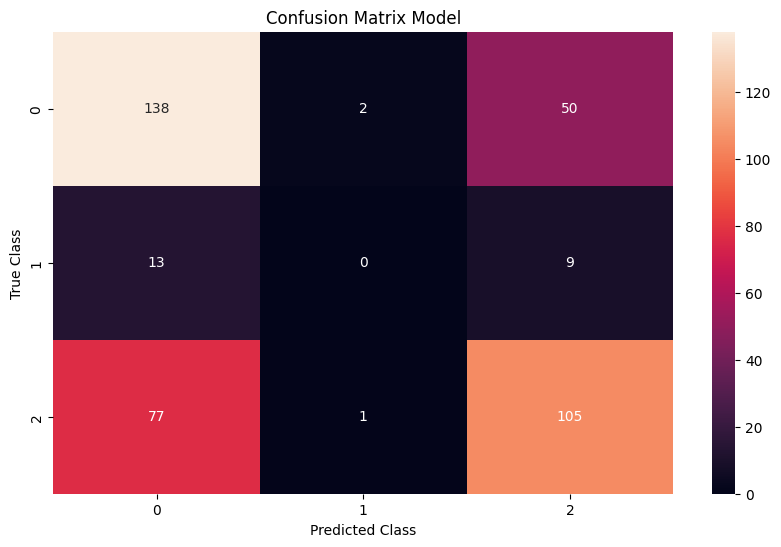

In [ ]:
fig = plt.figure(figsize = (10, 6))
sns.heatmap(cm, annot = True, fmt = "d")

# Labeling the X-axis
plt.xlabel("Predicted Class")

# Labeling the Y-axis
plt.ylabel("True Class")

# Give a title to the graph
plt.title("Confusion Matrix Model")

In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
# Inisialisasi K-Fold Cross Validation
kf = KFold(n_splits=20, shuffle=True, random_state=42)
kf
# Melakukan K-Fold Cross Validation
scores = cross_val_score(model, X_encoded, y_encoded, cv=kf, scoring='accuracy')
scores

array([0.78688525, 0.81147541, 0.70491803, 0.66393443, 0.74590164,
       0.77868852, 0.7295082 , 0.79508197, 0.71311475, 0.77868852,
       0.77868852, 0.81967213, 0.79508197, 0.74590164, 0.7704918 ,
       0.78512397, 0.78512397, 0.7768595 , 0.75206612, 0.75206612])

In [ ]:
print("Akurasi pada setiap fold:", scores)
print("Akurasi rata-rata:", scores.mean())

Akurasi pada setiap fold: [0.78688525 0.81147541 0.70491803 0.66393443 0.74590164 0.77868852
 0.7295082  0.79508197 0.71311475 0.77868852 0.77868852 0.81967213
 0.79508197 0.74590164 0.7704918  0.78512397 0.78512397 0.7768595
 0.75206612 0.75206612]
Akurasi rata-rata: 0.7634636228153366


## WordCloud Kata-kata yang Paling Sering Muncul untuk Setiap Label

In [ ]:
from collections import Counter

In [ ]:
review_column = df['tweet_clean']

In [ ]:
from collections import Counter
all_texts = ' '.join(df['tweet_clean'])
word_counts = Counter(all_texts.split())
most_common_words = word_counts.most_common(10)
for word, count in most_common_words:
    print(f"{word}: {count}")


tokopedia: 429
nya: 319
barang: 314
aplikasi: 282
yg: 279
kirim: 278
kurir: 276
gak: 239
beli: 230
belanja: 225


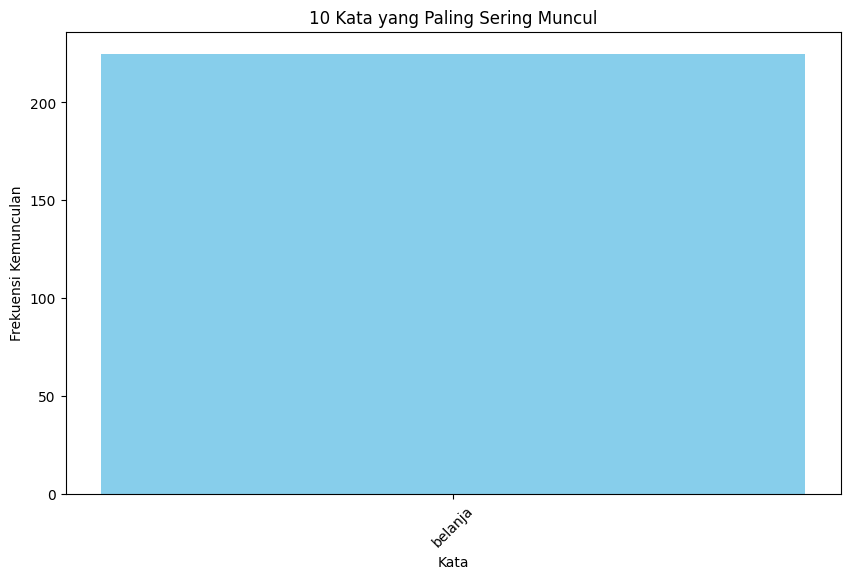

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(word, count, color='skyblue')
plt.xlabel('Kata')
plt.ylabel('Frekuensi Kemunculan')
plt.title('10 Kata yang Paling Sering Muncul')
plt.xticks(rotation=45)  # Untuk memutar label kata agar lebih mudah dibaca
plt.show()


In [ ]:
!pip install wordcloud

   ---------------------------------------- 0.0/300.2 kB ? eta -:--:--
   ---- ----------------------------------- 30.7/300.2 kB 1.4 MB/s eta 0:00:01
   ------- ------------------------------- 61.4/300.2 kB 825.8 kB/s eta 0:00:01
   --------------------- ------------------ 163.8/300.2 kB 1.4 MB/s eta 0:00:01
   ---------------------------------- ----- 256.0/300.2 kB 1.4 MB/s eta 0:00:01
   ---------------------------------------  297.0/300.2 kB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 300.2/300.2 kB 1.3 MB/s eta 0:00:00


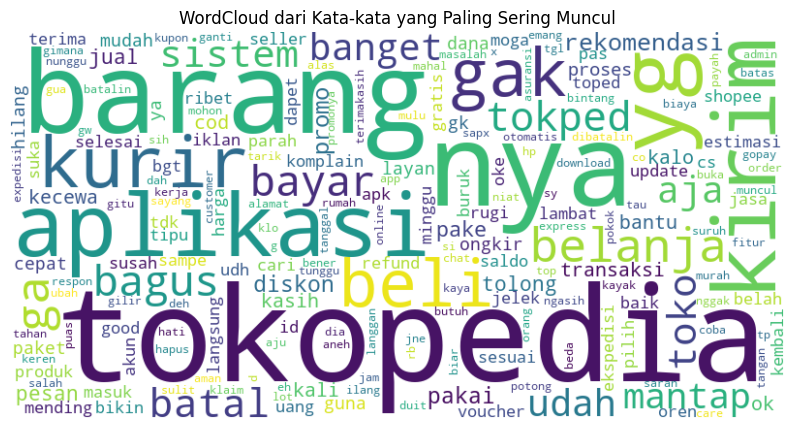

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Membuat WordCloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_counts)

# Menampilkan WordCloud
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Menghilangkan sumbu
plt.title('WordCloud dari Kata-kata yang Paling Sering Muncul')
plt.show()


In [ ]:
from collections import Counter

# Membagi teks berdasarkan label
texts_by_label = {}
for label in df['label'].unique():
    texts_by_label[label] = ' '.join(df[df['label'] == label]['tweet_clean'])

# Menghitung frekuensi kemunculan setiap kata dalam setiap kelompok teks
word_counts_by_label = {}
for label, text in texts_by_label.items():
    word_counts_by_label[label] = Counter(text.split())

# Mendapatkan 10 kata yang paling sering muncul untuk setiap kelompok teks
most_common_words_by_label = {}
for label, word_counts in word_counts_by_label.items():
    most_common_words_by_label[label] = word_counts.most_common(10)

# Mencetak kata-kata yang paling sering muncul untuk setiap kelompok teks
for label, most_common_words in most_common_words_by_label.items():
    print(f"Kata-kata paling sering muncul untuk label '{label}':")
    for word, count in most_common_words:
        print(f"{word}: {count}")
    print()


Kata-kata paling sering muncul untuk label '1':
mantap: 147
tokopedia: 145
bagus: 136
nya: 100
belanja: 95
ok: 95
bantu: 82
aplikasi: 77
mudah: 61
yg: 61

Kata-kata paling sering muncul untuk label '-1':
tokopedia: 265
barang: 252
kirim: 220
kurir: 215
gak: 194
aplikasi: 190
ga: 190
nya: 190
yg: 189
beli: 187

Kata-kata paling sering muncul untuk label '0':
kirim: 31
nya: 29
yg: 29
kurir: 23
tokopedia: 19
barang: 18
aplikasi: 15
gak: 15
bagus: 12
tolong: 12



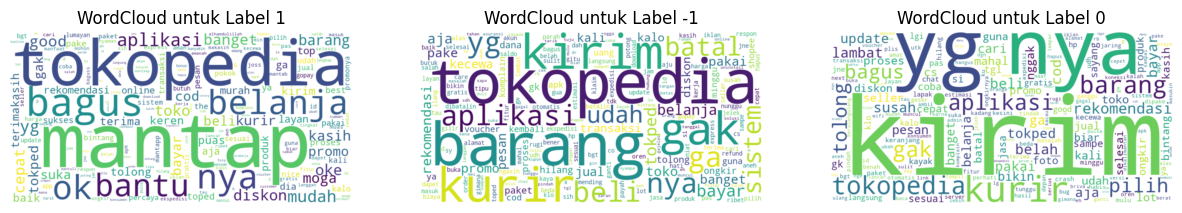

In [ ]:
plt.figure(figsize=(15, 10))
for i, (label, word_counts) in enumerate(word_counts_by_label.items()):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_counts)
    plt.subplot(1, len(word_counts_by_label), i+1)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'WordCloud untuk Label {label}')
    plt.axis('off')
plt.show()